# Protección frente al despido y empresas de alto crecimiento

In [ ]:
# Parámetros de la gráfica
SLUG = "economia"  # carpeta en research/temas/
GRAFICA_ID = "proteccion-empleo-empresas-alto-crecimiento"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Protección frente al despido y empresas de alto crecimiento"  # `titulo` de la gráfica en config.json
DESDE = 1976  # primer año candidato (METODOLOGIA §2.3)
UNIVERSO = "ocde"  # ocde | ue27: todos sus países con dato en los dos ejes (METODOLOGIA §2.6)
EJE_X = {"titulo": "Rigidez de la protección frente al despido", "unidad": "índice de 0 (menor) a 6"}
EJE_Y = {"titulo": "Empresas de alto crecimiento", "unidad": "% de las empresas con 10 o más asalariados"}
ANIOS = None  # (desde, hasta) si el config fija una ventana; None = último año común de cada país
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

Cada punto es un país de la OCDE con dato en los dos ejes.

- **Eje horizontal:** el indicador de la OCDE de **rigidez de la protección de los contratos indefinidos frente al despido**, individual y colectivo, de 0 (menor rigidez) a 6.
- **Eje vertical:** el porcentaje de **empresas de alto crecimiento**: empresas con al menos 10 asalariados que aumentan su plantilla más de un 10 % al año durante tres años seguidos, sobre el total de empresas con al menos 10 asalariados.

**Para qué sirve.** Pone junto a la protección frente al despido el argumento de quienes proponen reducirla: que una protección alta frena la contratación y el crecimiento de las empresas. Quienes proponen mantenerla sostienen que no es lo que limita su crecimiento (la comparación con el paro está en `proteccion-empleo-paro`): la gráfica permite las dos lecturas. **La relación entre dos indicadores no muestra que uno cause el otro**: no se dibuja línea de tendencia ni se calcula la correlación.

**Limitaciones.**
- El indicador de protección recoge lo que dice la ley, no cómo se aplica, y solo la de los contratos indefinidos.
- Las empresas de alto crecimiento miden el crecimiento del empleo, no el de las ventas, y solo se publican para parte de los países de la OCDE y con años distintos; cada punto usa el último año en que el país tiene dato en los dos ejes.
- El crecimiento de las empresas depende de muchos factores además de la regulación laboral (tamaño del mercado, financiación, trámites, impuestos).

## 2. Descarga

- **OCDE, indicadores de legislación de protección del empleo** (`OECD.ELS.JAI,DSD_EPL@DF_EPL`, versión 1.0): `EPL_OV`, metodología `VERSION4`, escala de 0 a 6 (el mismo eje que `proteccion-empleo-paro`).
- **OCDE, demografía empresarial** (`OECD.SDD.TPS,DSD_SDBSBD_ISIC4@DF_BD_EMP_HG`, versión 1.0): empresas de alto crecimiento (`HGE10`, `PT_ENT10`, `S_GE10`) de la actividad `BTNXK`.
- **Contrastes para las notas:** España en Eurostat (`bd_hgnace_r`), qué publica la OCDE de Canadá y la tasa de natalidad de empresas de España (`DF_BD_EMP_B_D`).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.paises import paises_de
from lib.writer import construir_dispersion_data, write_dispersion_data

PAISES = paises_de(UNIVERSO)

from datetime import date

from lib import eurostat, oecd
from lib.paises import nombre_punto
from lib.tipos import FuenteMeta

AREAS = {c: c for c in PAISES}  # todos los países del universo, con su código como clave de serie
HOY = date.today().isoformat()

# Protección del empleo (OCDE, indicadores EPL): contratos indefinidos, despidos individuales y colectivos
DATAFLOW_EPL = "OECD.ELS.JAI,DSD_EPL@DF_EPL,1.0"
# Dimensiones: frecuencia . país . medida . unidad (escala de 0 a 6) . versión de la metodología
MEDIDA_EPL = "EPL_OV"  # contratos indefinidos, despidos individuales y colectivos (EPL_R: solo individuales)
VERSION_EPL = "VERSION4"  # la más reciente: cubre España y 43 áreas desde 2013
CLAVE_EPL = "A.{AREA}." + f"{MEDIDA_EPL}.0_TO_6.{VERSION_EPL}"
# Empresas de alto crecimiento (demografía empresarial de la OCDE)
DATAFLOW_HG = "OECD.SDD.TPS,DSD_SDBSBD_ISIC4@DF_BD_EMP_HG,1.0"
# Dimensiones: frecuencia . país . medida (empresas) . actividad . tamaño (10 o más asalariados) . edad (todas)
#              . tipo (empresas con asalariados) . fase (crecimiento del empleo de más del 10 % anual) . unidad
ACTIVIDAD = "BTNXK"  # economía empresarial (secciones B a N de la CIIU/NACE) salvo actividades financieras y de seguros
CLAVE_HG = "A.{AREA}." + f"ENT.{ACTIVIDAD}.S_GE10._T.ENT_EMP.HGE10.PT_ENT10"
# Tasa de natalidad de las empresas con asalariados (solo notas)
DATAFLOW_NAT = "OECD.SDD.TPS,DSD_SDBSBD_ISIC4@DF_BD_EMP_B_D,1.0"
CLAVE_NAT = "A.{AREA}." + f"ENT.{ACTIVIDAD}._T.Y_LT1.ENT_EMP.B.PT_ENT_EM"


def descargar_hg():
    return oecd.get(DATAFLOW_HG, CLAVE_HG, areas=AREAS, desde=DESDE)


def otras_definiciones_hg(area):
    """Qué publica la OCDE de empresas de alto crecimiento para un país sin la definición de la gráfica.

    Con reintentos (`pedir`) y sin tragarse errores: si la consulta falla, el notebook falla en vez
    de escribir unas notas distintas.
    """
    import io

    import requests

    from lib._http import pedir

    r = pedir(
        requests.Session(), f"{oecd.BASE}/{DATAFLOW_HG}/A.{area}.ENT.......", None,
        error_cls=oecd.OecdError, etiqueta=f"empresas de alto crecimiento de {area}",
        mensaje=lambda r: r.text[:200], headers=oecd.CABECERA_CSV,
    )
    return pd.read_csv(io.StringIO(r.text), dtype=str)


def descargar_hg_eurostat():
    """Contraste de España con Eurostat (bd_hgnace_r)."""
    return eurostat.get(
        "bd_hgnace_r", {"freq": "A", "indic_sbs": "ENT_HGRWR_PC", "nace_r2": "B-S_X_O_S94"},
        geos={"ES": "ESP"}, desde=DESDE,
    )


def descargar_natalidad():
    return oecd.get(DATAFLOW_NAT, CLAVE_NAT, areas={"ESP": "ESP"}, desde=DESDE)[0]

x, _ = oecd.get(DATAFLOW_EPL, CLAVE_EPL, areas=AREAS, desde=DESDE)
y, _ = descargar_hg()
try:
    media_y, _ = oecd.get(DATAFLOW_HG, CLAVE_HG, areas={"OECD": "OECD", "EU27_2020": "EU27_2020"}, desde=DESDE)
except oecd.OecdError as e:
    assert "NoRecordsFound" in str(e), f"error distinto de «sin datos»: {e}"
    media_y = pd.DataFrame(columns=["serie", "periodo", "valor"])
hg_eurostat, _ = descargar_hg_eurostat()
natalidad = descargar_natalidad()
otras_can = otras_definiciones_hg("CAN")
print("Países con protección del empleo:", x["serie"].nunique(), "· con empresas de alto crecimiento:", y["serie"].nunique())

Países con protección del empleo: 38 · con empresas de alto crecimiento: 28


## 3. Transformación

1. Los dos ejes se usan tal como los publica la OCDE, sin transformar.
2. **Sin puntos de medias:** la OCDE no publica las empresas de alto crecimiento para su media ni para la UE-27 (se comprueba en la descarga).
3. El escritor elige para cada país el último año con dato en los dos ejes, el mismo para `x` e `y`.
4. Para las notas: el indicador de España y la comparación con Eurostat y la tasa de natalidad de empresas.

In [ ]:
def unir(xs):
    xs = [str(x) for x in xs]
    return xs[0] if len(xs) == 1 else f"{', '.join(xs[:-1])} y {xs[-1]}"


def es(v, d=1):
    return estilos.formato_es(v, d)


def notas_epl(x, v):
    """Notas comunes del eje de la protección frente al despido (OCDE, EPL)."""
    _, flujo, version = DATAFLOW_EPL.split(",")
    notas = [
        f"Protección del empleo: OCDE, indicadores de legislación de protección del empleo ({flujo}, versión {version}): "
        f"indicador {MEDIDA_EPL} (contratos indefinidos, despidos individuales y colectivos), escala de 0 (menor "
        f"rigidez) a 6, metodología {VERSION_EPL}. Mide lo que dice la ley, no cómo se aplica.",
    ]
    esp = x[x["serie"] == "ESP"].set_index("periodo")["valor"]
    if len(esp):
        cambios = esp[esp.diff().abs() > 1e-9].index.tolist()
        notas.append(
            f"La serie de España empieza en {int(esp.index.min())}, después de la reforma laboral de 2012, y la fuente "
            f"solo cambia su valor en {unir(cambios) if cambios else 'ningún año'}; la reforma de 2021 actuó sobre "
            "todo en la contratación temporal, que este indicador no recoge."
        )
    return notas


def notas_hg(y, hg_eurostat, natalidad, otras_can):
    """Notas comunes del eje de las empresas de alto crecimiento."""
    _, flujo, version = DATAFLOW_HG.split(",")
    notas = [
        f"Empresas de alto crecimiento: OCDE, demografía empresarial ({flujo}, versión {version}): empresas con al "
        "menos 10 asalariados al inicio del periodo cuyo número de asalariados crece de media más de un 10 % al año "
        "durante tres años, en porcentaje de las empresas con al menos 10 asalariados (HGE10, PT_ENT10, S_GE10).",
        f"Actividad: economía empresarial salvo actividades financieras y de seguros ({ACTIVIDAD}, secciones B a N "
        "salvo K), el agregado de actividad con más países de la OCDE en esta definición.",
        "Mide el crecimiento del empleo, no el de la facturación, y no cuenta las empresas sin asalariados ni las "
        "que no crecen, a diferencia de la tasa de natalidad de empresas.",
    ]
    can = otras_can
    if len(can) and "HGE10" not in set(can["BUSINESS_STAGE"]):
        etapas = sorted(set(can["BUSINESS_STAGE"]) & {"HGE20", "HGT20", "HGE10T20"})
        notas.append(
            "Canadá no aparece: la OCDE solo publica sus empresas de alto crecimiento con otra definición "
            f"({unir(etapas)}: crecimiento de más del 20 % anual), sin la del 10 % de esta gráfica."
        )
    esp = y[y["serie"] == "ESP"].set_index("periodo")["valor"]
    eu = hg_eurostat.set_index("periodo")["valor"]
    comunes = sorted(set(esp.index) & set(eu.index))
    if comunes:
        a = comunes[-1]
        notas.append(
            f"España en Eurostat (bd_hgnace_r, industria, construcción y servicios salvo administración pública y "
            f"asociaciones, B-S_X_O_S94): {es(eu[a], 2)} % en {a}, frente al {es(esp[a], 2)} % de la OCDE ({ACTIVIDAD}); "
            "las dos fuentes no cubren las mismas actividades."
        )
    if len(natalidad):
        n = natalidad.sort_values("periodo").iloc[-1]
        notas.append(
            f"Tasa de natalidad de las empresas con asalariados de España (OCDE, {DATAFLOW_NAT.split(',')[1]}, "
            f"{ACTIVIDAD}): {es(n['valor'])} % de las empresas activas en {int(n['periodo'])}. No se usa en la gráfica: "
            "cuenta todas las empresas nuevas, también las pequeñas que no crecen."
        )
    return notas


assert media_y.empty, f"La OCDE publica las empresas de alto crecimiento de {sorted(media_y['serie'].unique())}: revisar si se añade el punto"
_, FLUJO_EPL, VERSION_EPL_FLUJO = DATAFLOW_EPL.split(",")
fuentes = [
    FuenteMeta("eje_x", oecd.ORGANISMO, f"{FLUJO_EPL} (EPL, versión {VERSION_EPL_FLUJO}): {MEDIDA_EPL}, 0_TO_6, {VERSION_EPL}", oecd.URL_EXPLORER, HOY),
    FuenteMeta("eje_y", oecd.ORGANISMO, f"{DATAFLOW_HG.split(',')[1]}: HGE10, PT_ENT10, S_GE10, {ACTIVIDAD}", oecd.URL_EXPLORER, HOY),
]
NOTAS = notas_epl(x, VERSION_EPL) + [
    "Sin punto de la media OCDE ni de la UE-27: la OCDE no publica las empresas de alto crecimiento para esos agregados.",
] + notas_hg(y, hg_eurostat, natalidad, otras_can)

## 4. Visualización

Un punto por país, sin línea de tendencia ni correlación (METODOLOGIA §2.6).

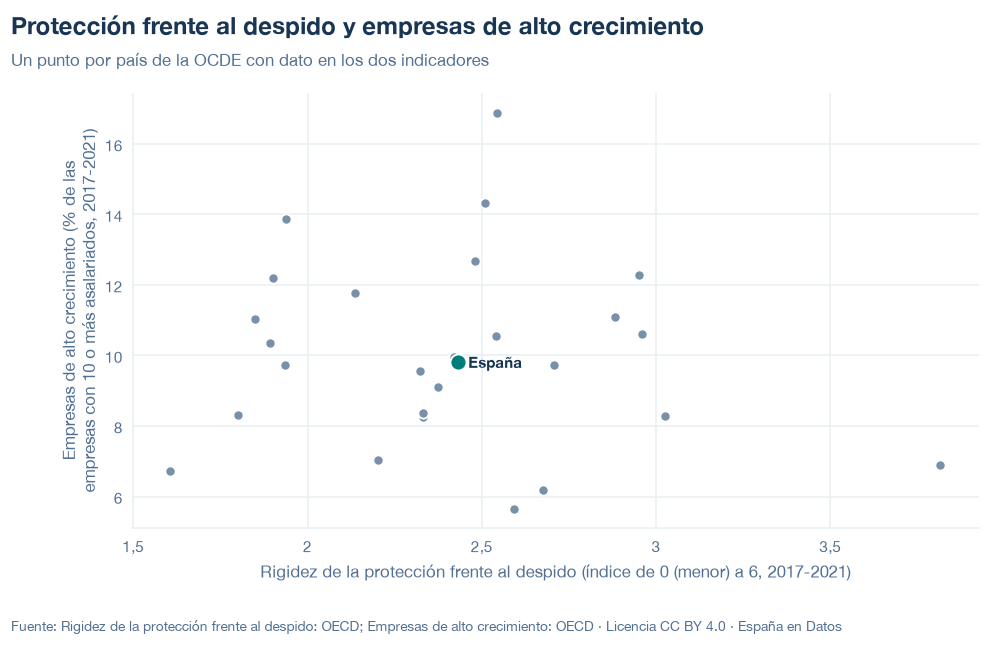

codigo  anio        x         y
   AUT  2021 1.800631  8.319125
   BEL  2021 2.591117  5.656941
   CHE  2017 1.606974  6.722480
   CZE  2021 3.025262  8.284117
   DEU  2021 2.332411  8.247173
   DNK  2021 1.937693 13.881402
   ESP  2021 2.430514  9.813936
   EST  2021 1.934223  9.720605
   FIN  2021 2.479751 12.693133
   FRA  2021 2.675937  6.194945
   GBR  2018 1.901724 12.210964
   GRC  2021 2.508901 14.338316
   HUN  2020 1.892335 10.340394
   IRL  2021 2.134929 11.776052
   ISL  2020 2.203089  7.023604
   ITA  2021 3.815954  6.895741
   LTU  2021 1.848945 11.026698
   LUX  2021 2.541837 10.541248
   LVA  2021 2.708121  9.718193
   NLD  2021 2.880873 11.084942
   NOR  2020 2.373485  9.100798
   POL  2021 2.421032  9.948272
   PRT  2021 2.961044 10.599048
   SVK  2021 2.330605  8.364553
   SVN  2021 2.322110  9.570008
   SWE  2021 2.544405 16.889853
   TUR  2020 2.949661 12.285948


In [ ]:
datos = construir_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
)
fig = estilos.figura(datos, titulo=TITULO)
estilos.mostrar(fig)
print(pd.DataFrame(datos["puntos"]).to_string(index=False))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web (`codigo;pais;anio;eje_x;eje_y`).

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_dispersion_data(
    x, y, fuentes, id=GRAFICA_ID, universo=UNIVERSO, eje_x=EJE_X, eje_y=EJE_Y, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, anios=ANIOS,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/proteccion-empleo-empresas-alto-crecimiento.json y data/proteccion-empleo-empresas-alto-crecimiento.csv


## 6. Fuentes, notas y licencia

- OCDE, indicadores de protección del empleo: `OECD.ELS.JAI,DSD_EPL@DF_EPL,1.0` (`EPL_OV`, `0_TO_6`, `VERSION4`).
- OCDE, demografía empresarial: `OECD.SDD.TPS,DSD_SDBSBD_ISIC4@DF_BD_EMP_HG,1.0` y `DF_BD_EMP_B_D` (natalidad, solo notas).
- Eurostat, `bd_hgnace_r` (contraste de España).

La fecha de consulta de cada eje está en `fuentes` del JSON; las notas incluyen los países sin dato y la advertencia de que la relación no muestra causa.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.